# **Mission 3 - Exploratory Data Analysis (EDA) with the Sales Dataset using Pandas and d Matplotlib/Seaborn**

### **Objective:**

The goal of this assignment is to help you apply your knowledge of Python for basic operations, Pandas for data manipulation, and Matplotlib/Seaborn for visualizations. You'll be working with a real-world dataset, and your tasks will include loading the data, performing EDA, and visualising the results.

###  **Dataset**

The dataset represents transaction data from a retail business, specifically sales data for products sold in various stores. It contains multiple tables that provide insights into sales, invoices, and products. Let’s break down the tables and what they represent:

#### Sales Table:

InvoiceNo: The unique identifier for each invoice (or transaction).

StockCode: A unique identifier for each product.

Quantity: The number of units sold in each transaction.

UnitPrice: The price per unit of the product.

InvoiceDate: The date when the transaction occurred.

#### Invoice Table:

InvoiceNo: The same unique identifier for each invoice, linking the sales data with the invoice details.

Country: The country where the sale was made.

#### Product Table:

StockCode: A unique identifier for each product.

Description: The name or description of the product.

Product_Category: The category the product belongs to (e.g., "Gift", "Sign", "Mug").



You will need to merge them and perform the following tasks step by step.


### Task 1: Load the Excel File
#### Objective: Import the data from the provided Excel file into Python using Pandas.

Instructions:

1. Upload the provided excel file into Fabric environment
2. Read each sheet of the excel file as a separate dataframe. 
3. Name the dataframe for sales as df_sales, the dataframe for invoice as df_invoice and the dataframe for product as df_product
4. Display the first few rows of each DataFrame to understand its structure.



In [52]:
### Code Task Here

# Load pandas library into this script and assign as name pd
import pandas as pd

# We now load the Excel dataset OnlineSalesRetailer1.xlsx 
# This dataset has 3 tables and we named these dataframes: df_sales for Sales, df_invoice for Invoice and df_products for Products
df_sales = pd.read_excel(f"{notebookutils.nbResPath}/builtin/OnlineSalesRetailer1.xlsx", sheet_name='Sales')

df_invoice = pd.read_excel(f"{notebookutils.nbResPath}/builtin/OnlineSalesRetailer1.xlsx", sheet_name='Invoice')

df_product = pd.read_excel(f"{notebookutils.nbResPath}/builtin/OnlineSalesRetailer1.xlsx", sheet_name='Product')

# Display the first few rows the 3 tables
print("----------------SALES TABLE----------------")
display(df_sales.head())

print("----------------INVOICE TABLE----------------")
display(df_invoice.head())

print("----------------PRODUCT TABLE----------------")
display(df_product.head())

----------------SALES TABLE----------------


----------------INVOICE TABLE----------------


----------------PRODUCT TABLE----------------


### Task 2: Basic Python and Pandas Operations
#### Objective: Perform basic Python and Pandas operations to manipulate the data.

<mark>Instructions:</mark>

1. Create the Sales Column (Quantity * Unit Price) 

2. Check for missing values in the Sales DataFrame.

3. Replace any NaN values in the Sales and UnitPrice columns with 0.

4. Calculate basic descriptive statistics for the Quantity and UnitPrice columns (mean, median, mode, standard deviation).

In [53]:
## Code Task 2 here

# No.1 - Creating the Sales Column (Quantity * Unit Price)
# This step calculates the total revenue for every transaction
# by multiplying the Quantity column and the UnitPrice,
# and saves the result in a new "Sales" column.
df_sales["Sales"] = df_sales["Quantity"] * df_sales["UnitPrice"]

# View the result
display(df_sales.head())

In [54]:
# Check each column for missing values (NaN)
# True = column contains missing values
# False = column contains no missing values
# reset_index() converts the result into a table format
# .any(): Checks each column to see if there is at least one
missing_values = df_sales.isnull().any().reset_index()

# View the table
display(missing_values)

In [55]:
# No.3 - Replace any Nan values with 0 specifically in the Sales and UnitPrice columns
df_sales["Sales"] = df_sales["Sales"].fillna(0)
df_sales["UnitPrice"] = df_sales["UnitPrice"].fillna(0)

# Show the result
display(df_sales)

In [56]:
# Check for 0 values in Sales and UnitPrice column
display(df_sales[(df_sales["Sales"] == 0) & (df_sales["UnitPrice"] == 0)])

In [57]:
# Calculate basic descriptive statistics for the Quantity and UnitPrice
# mean: gives average value
# median: is the middle value when data is sorted
# std: stands for Standard deviation, which measures how spread out the values are
# mode: is the most frequent value

# For Quantity
print("--- Quantity Stats ---")
print("Mean:", df_sales["Quantity"].mean())
print("Median:", df_sales["Quantity"].median())
print("Standard Deviation:", df_sales["Quantity"].std())
print("Mode:", df_sales["Quantity"].mode()[0])

# For UnitPrice
print("\n--- UnitPrice Stats ---")
print("Mean:", df_sales["UnitPrice"].mean())
print("Median:", df_sales["UnitPrice"].median())
print("Standard Deviation:", df_sales["UnitPrice"].std())
print("Mode:", df_sales["UnitPrice"].mode()[0])

--- Quantity Stats ---
Mean: 13.610961009642518
Median: 6.0
Standard Deviation: 261.57756533207146
Mode: 1

--- UnitPrice Stats ---
Mean: 3.0835027678710816
Median: 1.95
Standard Deviation: 5.177652565375899
Mode: 1.25


### Task 3: Merging DataFrames
#### Objective: Merge the Sales, Invoice, and Product tables based on common keys to perform a comprehensive analysis.

Instructions:

1. Merge the Sales DataFrame with the Invoice DataFrame on InvoiceNo.

2. Merge the result with the Product DataFrame on StockCode

In [58]:
## Code Task 3 here

# Combined the df_sales and df_invoice table using their common keys "InvoiceNo".
df_combined = pd.merge(df_sales, df_invoice, on="InvoiceNo")

# Display the result.
display(df_combined.head())

In [59]:
# Now we combined the df_product table to the newly merge table named df_combined(df_sales and df_invoice)
df_combined_product = pd.merge(df_combined, df_product, on="StockCode")

# Display the result.
display(df_combined_product.head())

## Task 4: Exploratory Data Analysis (EDA)
### Objective: Conduct EDA by analysing the data, identifying patterns, trends, and outliers.

Instructions:

Use describe() to calculate summary statistics for numeric columns.

Perform basic filtering, such as filtering out sales with Quantity equal to 0.

Check for outliers in the Sales column by using a scatter plot.

In [60]:
## Code Task 4 here

# First we need to install Seaborn and Matplotlib. These are python tools for making charts and graphs.
# Seaborn makes it easy to draw clean, beautiful charts quickly, while Matplotlib is the 
# underlying engine that lets you customize every single detail of your pictures.
!pip install seaborn matplotlib

In [61]:
# Calculation and summary statistics for the 3 tables (df_sales, df_products and df_invoice).

# .describe() function in python is a quick way to generate a statistical summary of the numerical
# columns in our dataset.

# Metrics shows and calculates: count, mean, std, min, 25%, 50%, 75% and max.

# I used the df_combined_product becuase this table is the final merge of 3 tables(sales, invoice, product).
display(df_combined_product.describe().reset_index())

In [62]:
# Filtering out Sales with Quantity equal to 0.
df_filtered = df_combined_product[df_combined_product["Quantity"] > 0]

# Display
display(df_filtered.head()) # at this report shows there is no equal to 0 in the Quantity column.

In [63]:
# Count how many 0s are left in the filtered data
(df_filtered["Quantity"] == 0).sum()

0

In [64]:
# Check the new minimum value (it should no longer be 0)
df_filtered["Quantity"].min()

1

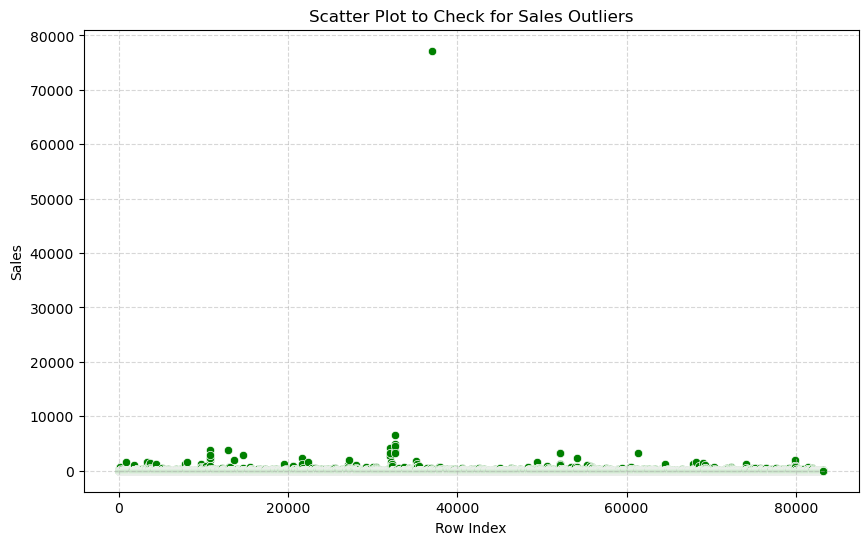

In [65]:
# This code is to create a scatterplot to visualize sales data across different countries,
# helping easily spot any unusual values or outliers.

# Loads the two Python libraries used for data visualization and making charts
import matplotlib.pyplot as plt
import seaborn as sns

# Sets the size of the output image to a square format, so the chart is large and easy to read
plt.figure(figsize=(10, 6))

# sns: this is short for Seaborn
# scatterplot: tells python to draw a scotter plot
# x=df_filtered.index: this sets the horizontal baseline (x-axis) of the graph
# y=df_filtered["Sales"]: this sets the vertical height (y-axis) 
# of each dot based on the total dollar amount in the "Sales" column
# I used the df_filtered now because, before we did the filtering out sales with quantity equal to 0.
sns.scatterplot(x=df_filtered.index, y=df_filtered["Sales"], color="green")

# Adds a title and labels the axes
plt.title("Scatter Plot to Check for Sales Outliers")
plt.xlabel("Row Index")
plt.ylabel("Sales")
plt.grid(True, linestyle="--", alpha=0.5) # background lines of the chart to make it easier to read

# Display the final chart
plt.show()

<mark>The scatter plot clearly highlights the extreme data outlier around Row 36,980, where a single transaction spikes to nearly $77,183 in sales—sitting completely isolated far above the dense cluster of normal transactions clustered near the bottom.</mark>

## Task 5: Data Visualisation – Scatter Plot, Histogram, and Line Chart
### Objective: Create scatter plots, histograms, and line charts to better understand the data.

Instructions:

Use a scatter plot to examine the relationship between Quantity and Sales.

Use a histogram to visualise the distribution of the Sales column.

Use a line chart to show the trend of Sales over time.

Write 1–2 sentences explaining the insights from each visualisation.

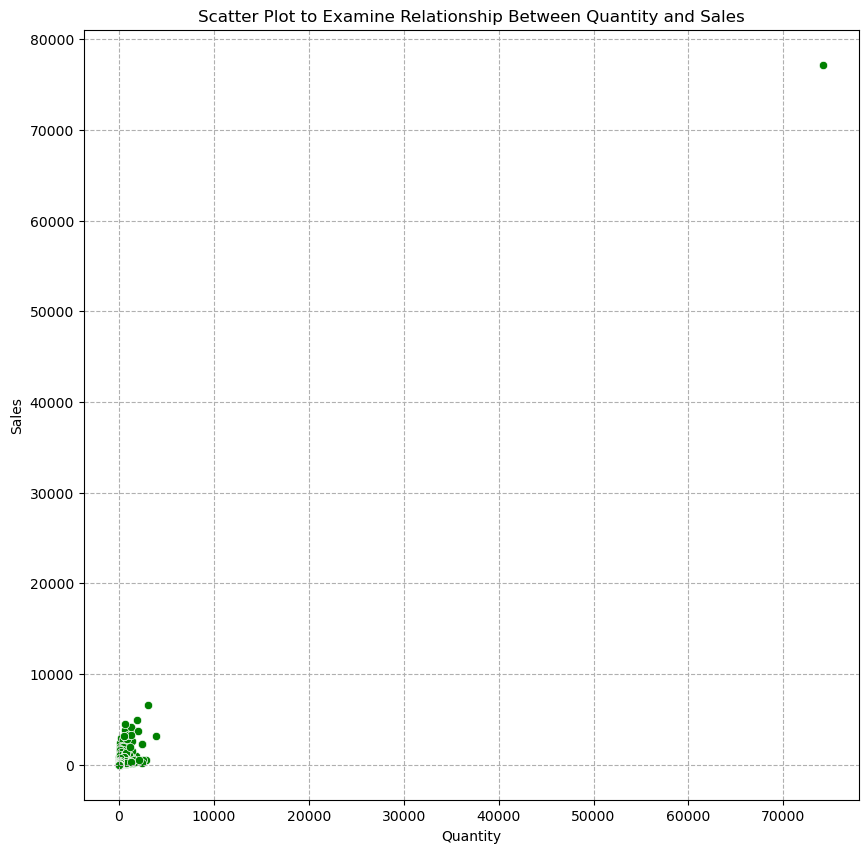

In [66]:
## Code Task 5 here

# Use a scatter plot to examine the relationship between Quantity and Sales.

# Loads the Python libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Sets the size of the output image
plt.figure(figsize=(10, 10))

# sns.scatterplot: Tells Python to create a scatter plot.
# x="Quantity": Sets the horizontal axis to show the "Quantity" column.
# y="Sales": Sets the vertical axis to show the total "Sales" column.
# data=df_sales: Tells python to pull these columns from a dataset named df_filtered.
# color="green": Makes all the dots on the chart green.
sns.scatterplot(x="Quantity", y="Sales", data=df_filtered, color="green")

# Adds a title and labels the axes
plt.title("Scatter Plot to Examine Relationship Between Quantity and Sales")
plt.xlabel("Quantity")
plt.ylabel("Sales")
plt.grid(True, linestyle="--")

# Display
plt.show()

<mark>This scatter plot maps Quantity against Sales. It demonstrates a tight cluster of standard transactions in the bottom left, while visually highlighting the extreme outlier far off to the right—where an exceptionally large quantity (74,215 items) generated roughly $77,183 in sales.</mark>

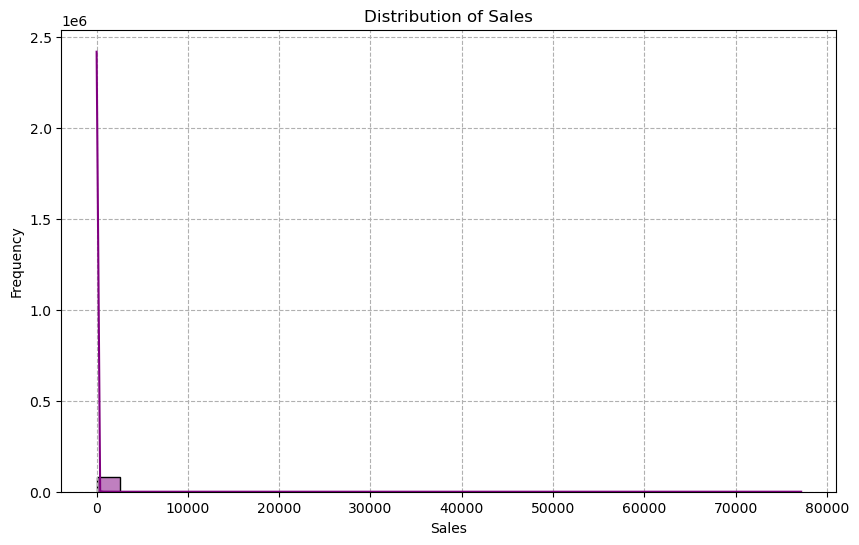

In [67]:
# Use a histogram to visualise the distribution of the Sales column.

# Loads the Python libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the figure size
plt.figure(figsize=(10, 6))

# sns.histplot(): Tells Seaborn to create a histogram, 
# which groups numerical sales data into ranges (bins) and 
# shows how often (frequency) values fall into each range.

# df_filtered['Sales']: Specifies the column from the dataset to analyze.
# bins=30: Divides the data into 30 different bars/intervals to give detailed view of the distribution.
# kde=True: Adds a smooth curve over the histogram to help you easily see the overall shape of the data distribution.
# color='purple': Colors the bar purple.
sns.histplot(df_filtered['Sales'], bins=30, kde=True, color='purple')

# Adds a title and labels the axes
plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.grid(True, linestyle="--")

# Show result
plt.show()

<mark>This histogram illustrates the distribution of sales values. It shows that the vast majority of transactions are heavily concentrated near zero (with a massive frequency peak), while the extreme outlier stretches all the way out near $77,183 on the far right.<mark></mark></mark>

In [68]:
# Extract Year-Month from InvoiceDate and convert directly to a datetime timestamp
# Convert the InvoiceDate datetime column into a Year-Month string format ("YYYY-MM") 
# to group and aggregate monthly sales cleanly for the time-series line chart
df_filtered["YearMonth"] = df_filtered["InvoiceDate"].dt.strftime("%Y-%m")

# Display result
display(df_filtered.head())

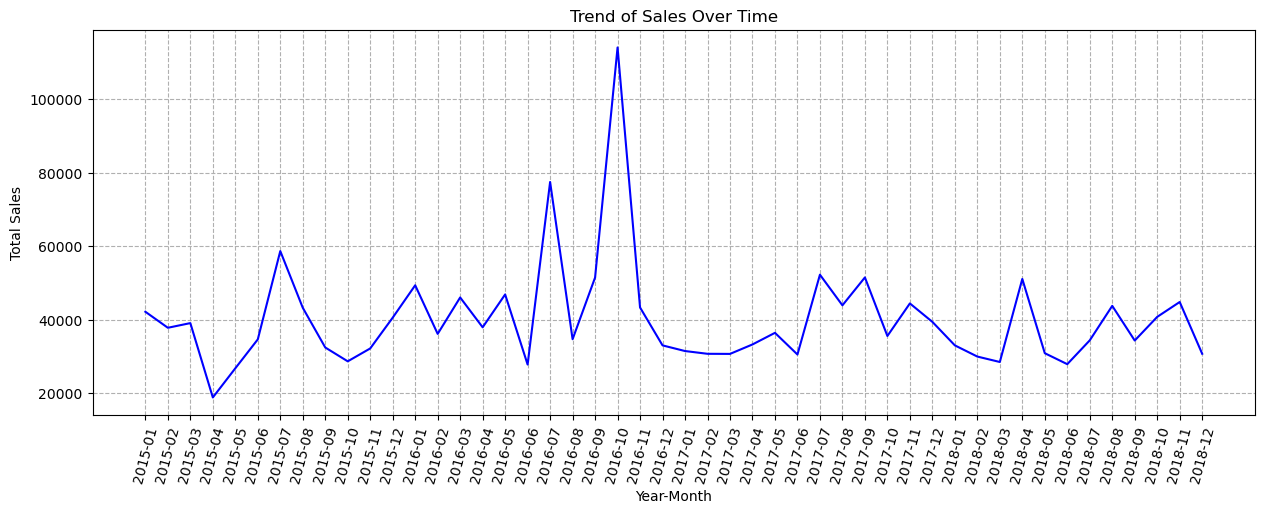

In [69]:
# Use a line chart to show the trend of Sales over time.

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15,5))

# sales_over_time = ...: Groups the filtered dataset by the YearMonth column, 
# sums up the Sales for each month, and resets the index to keep the output as a clean table.
sales_over_time = df_filtered.groupby("YearMonth")["Sales"].sum().reset_index()

# Draws a continuous blue line chart using YearMonth on the x-axis and the aggregated Sales on the y-axis.
sns.lineplot(x="YearMonth", y="Sales", data=sales_over_time, color='blue')

plt.title('Trend of Sales Over Time')
plt.xlabel('Year-Month')
plt.ylabel('Total Sales')

# Tilts the date labels on the x-axis by 75 degrees so they don't overlap and crowd each other.
plt.xticks(rotation=75)

# Adds a subtle dashed background grid to make it easier to trace values across the chart.
plt.grid(True, linestyle="--")

# Show the plot line
plt.show()

<mark>This line chart maps total monthly sales over time from 2015 to 2018. It reveals a stable baseline of monthly revenue with regular seasonal fluctuations, punctuated by major sales spikes in July 2016 and a peak performance in October 2016.</mark>

## Task 6: Correlation and Data Insights
### Objective: Identify the relationship between different numerical columns in the dataset.

Instructions:

Calculate the correlation between Quantity and Sales.

Visualise the correlation matrix using a heatmap.

Write 1–2 sentences explaining the insights from the visualisation.

          Quantity     Sales
Quantity  1.000000  0.978609
Sales     0.978609  1.000000


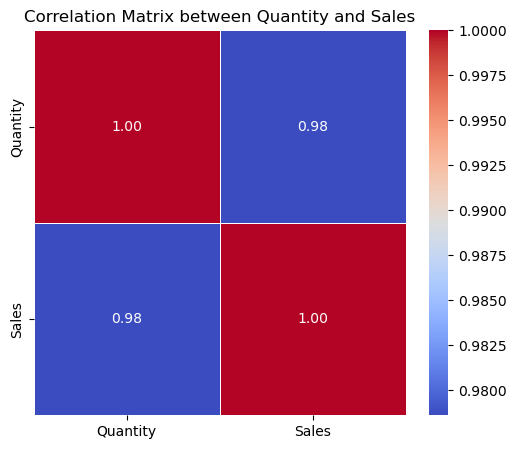

In [70]:
## Code Task 6 here

# Selects just the Quantity and Sales columns and computes their correlation matrix using Pearson's correlation method.
correlation = df_filtered[['Quantity', 'Sales']].corr()

# Outputs the numeric correlation table directly to your console or output window.
print(correlation)

# Sets the physical dimensions and size of the chart canvas.
plt.figure(figsize=(6,5))

# sns.heatmap(...): Creates the graphical heatmap using Seaborn
# annot=True: Displays the actual correlation numbers directly inside each colored cell.
# cmap='coolwarm': Uses a blue-to-red color gradient scheme.
# fmt='.2f': Formats the numbers inside the cells to show 2 decimal places.
# linewidths=0.5: Adds clean white gridlines between the cells for readability.
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
# plt.title(...): Sets a descriptive title above the heatmap chart.
plt.title('Correlation Matrix between Quantity and Sales')

# Display
plt.show()

<mark>This output is a correlation matrix, which measures the statistical relationship between two numeric columns (Quantity and Sales).

The values always range between -1.0 and +1.0. Here is how to read the specific result:
- The Score (0.978609): A correlation coefficient close to +1.0 indicates a very strong positive linear relationship.
- What it means for data: As the quantity of items purchased goes up, the total sales amount increases proportionally and very consistently. This makes logical sense because Sales formula is simply Quantity x UnitPrice.
- The diagonal (1.000000): This is just a variable compared against itself(Quantity vs Quantity, or Sales vs. Sales), which will always result in a perfect correlation of 1.

Essentially, it confirms that quantity is the overwhelming driver of total sales variance in this dataset.</mark>

## Task 7: Grouping and Aggregating
### Objective: Perform grouping and aggregation operations to summarise the data.

Instructions:

GroupBy operation: Group by Product_Category and calculate the total Sales per category.

Create a Pivot Table to show Sales by Country and Product_Category.

In [71]:
## Code Task 7 here

In [72]:
# groupby('Product_Category'): Splits rows into separate groups for each unique product category
# ['Sales'].sum(): Looks at the sales column for each category and adds them all together
# .reset_index(): Converts the resulting data structure back into a clean, flat table(DataFrame) rather than a multi-index series
df_category_sales = df_filtered.groupby('Product_Category')['Sales'].sum().reset_index()

# Show result
display(df_category_sales)

In [73]:
# A pivot table is a tool used to summarize and group data, similar to pivot tables in Excel.

# values="Sales": to look at the numbers and summarize are in the sales column
# index=["Country", "Product_Category"]: group the data. It sorts your rows first by Country, 
# and then breaks it down further by Product Category within each country.
pivot_sales = df_filtered.pivot_table(values="Sales", index=["Country", "Product_Category"])

# Display
display(pivot_sales.reset_index())

<mark>When examining the pivot table, you can notice a couple of interesting unusual and data inconsistencies that are worth pointing out:

1. Inconsistent Country Naming ("AUS" vs. "Australia"): You will notice separate rows for AUS (30 transactions) and Australia (277 transactions). In a fully cleaned production dataset, these two should be merged into a single "Australia" category to prevent fragmented reporting.

2. Many Zero Cells: Because there are so many distinct Product_Category columns (dozens of categories) spread across many countries, a huge portion of the pivot table cells show 0.00. This happens because many countries only purchase items from a few specific categories, leaving zero values everywhere else.

3. "Unspecified" as a Country: There is an Unspecified row in the country index, representing transactions where the country location data was missing or not recorded at entry.</mark>

## Submission Guidelines:
Submit the Python notebook with all the tasks and visualisations.

Ensure that each task is clearly explained and that all steps are followed.

Include markdown explanations where necessary to explain your thought process.

Good work